### Import Statements

In [2]:
import matplotlib.pyplot as plt
import numpy as np

### Part 1a - Shear Diagram

You will create your shear diagram in the code block below.


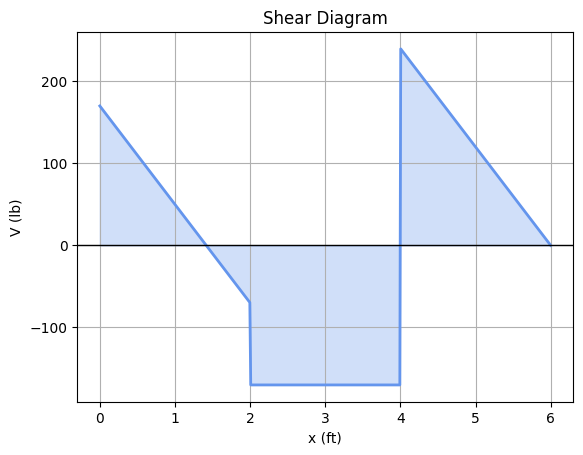

In [3]:
# Define beam variables and external forces
L = 6
R_A = 170
R_B = 410
P_1 = 100
q_1 = 120
q_2 = 120

# Define x using np.linspace
x = np.linspace(0, L, 500)

# Define v using np.zeros_like with x as argument
V = np.zeros_like(x) # creates a new list filled entirely with zeros, and it makes sure that the new list is the exact same size and shape as the old one.

# Use a for loop to define the piecewise function for shear force V
for i in range(len(x)):
    val = x[i] # ai helped me learn that val = x[i] just grabs the exact number stored at that current spot and saves it into a temporary variable called val so that we can do math on it
    if val < 2:
        V[i] = R_A - (q_1 * val)
    elif val > 4:
        V[i] = R_A - (q_1 * 2) - P_1 + R_B - (q_2 * (val - 4))
    else:
        V[i] = R_A - (q_1 * 2) - P_1

# Plot x against V, fill the area, and add standard formatting
plt.plot(x, V, color='cornflowerblue', linewidth=2)
plt.fill_between(x, V, color='cornflowerblue', alpha=0.3)
plt.axhline(0, color='black', linewidth=1)
plt.title('Shear Diagram')
plt.xlabel('x (ft)')
plt.ylabel('V (lb)')
plt.grid(True)
plt.show()

### Part 1b - Moment Diagram

You will create your moment diagram in the code block below.

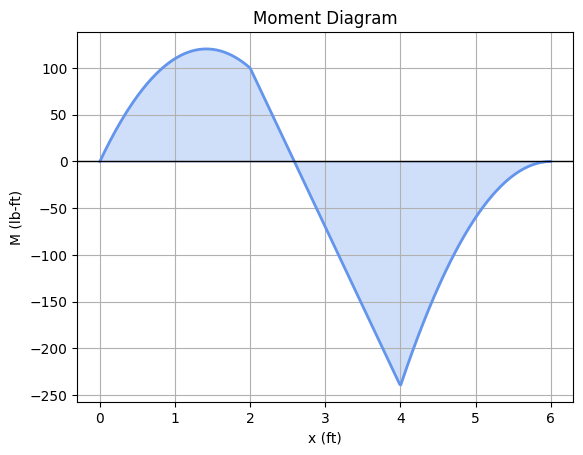

In [4]:
# Copy and paste variables from Part 1a
L = 6
R_A = 170
R_B = 410
P_1 = 100
q_1 = 120
q_2 = 120

# Define x using np.linspace
x = np.linspace(0, L, 500)

# Define M using np.zeros_like with x as the argument
M = np.zeros_like(x)

# Use a for loop to define the piecewise function for bending moment M
for i in range(len(x)):
    val = x[i] # ai helped me learn that val = x[i] just grabs the exact number stored at that current spot and saves it into a temporary variable called val so that we can do math on it
    if val < 2:
        M[i] = (R_A * val) - (q_1 * (val**2) / 2)
    elif val > 4:
        M[i] = (R_A * val) - (q_1 * 2 * (val - 1)) - (P_1 * (val - 2)) + (R_B * (val - 4)) - (q_2 * (val - 4) * ((val - 4) / 2))
    else:
        M[i] = (R_A * val) - (q_1 * 2 * (val - 1)) - (P_1 * (val - 2))

# Plot x against M, fill the area, and add standard formatting
plt.plot(x, M, color='cornflowerblue', linewidth=2)
plt.fill_between(x, M, color='cornflowerblue', alpha=0.3)
plt.axhline(0, color='black', linewidth=1)
plt.title('Moment Diagram')
plt.xlabel('x (ft)')
plt.ylabel('M (lb-ft)')
plt.grid(True)
plt.show()

### Part 2 - Pasadena Precipitation Data

You will now create a graph using Pasadena Temperature Data from 2013-2014.


### Numpy Array Creation & Slicing

Create and slice the array to create the x and y-axis values. These will correspond to the following columns in the CSV linked on readthedocs:

*   x - Date
*   y_1 - High Temperature
*   y_2 - Low Temperature

In [22]:
# Import the table from the CSV file into a 2D array of strings
array1 = np.genfromtxt('2013-2014-Pasadena-Temperature-Data.csv', delimiter=',', dtype=str, skip_header=1)

# Slice the array for the Date column and convert to datetime format
x = array1[:, 0].astype('datetime64') # ai helped learn the 'datetime64' callout, which basically just tells Python to treat the text like an actual calendar date, not just regular words or a string.

# Slice the array for High Temperature
y_1 = array1[:, 1].astype(float)

# Slice the array for Low Temperature
y_2 = array1[:, 2].astype(float)

### Graphing the Data

Plot x, y_1 and y_2 with the elements shown in the instructions on the HW page.

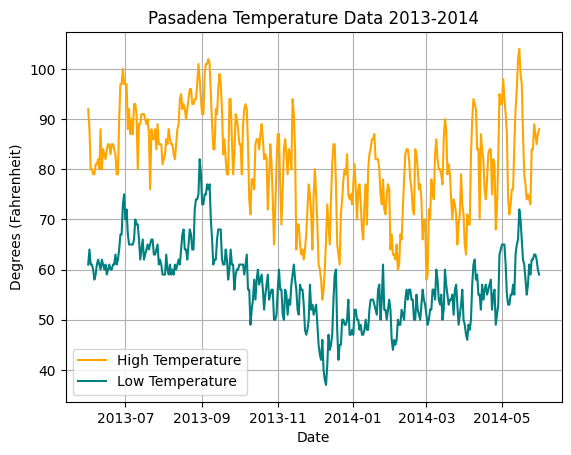

In [13]:
# Plot high and low temperature data with custom colors and labels
plt.plot(x, y_1, label='High Temperature', color='orange')
plt.plot(x, y_2, label='Low Temperature', color='teal')

# Add the title and axis labels
plt.title('Pasadena Temperature Data 2013-2014')
plt.xlabel('Date')
plt.ylabel('Degrees (Fahrenheit)')

# Add a legend and gridlines
plt.legend()
plt.grid(True)

# Display the completed graph
plt.show()

### Part 3 - Provo River Streamflow Data

You will now create a graph using streamflow data of the Provo River in June 2021.

### Numpy Array Creation & Slicing

Create and slice the array to create the x and y-axis values. These will correspond to the following columns in the CSV linked on the HW instructions page:

*   x - Date
*   y_1 - Site 10163000
*   y_2 - Site 10155200
*   y_3 - Site 10155500
*   y_4 - Site 10154200
*   y_5 - Site 10155000

In [21]:
# Import Provo River streamflow CSV file into a 2D array of strings
array1 = np.genfromtxt('June-2021-Provo-River-Streamflow-Rates.csv', delimiter=',', dtype=str, skip_header=1)

# Slice the columns and convert data types
x = array1[:, 0].astype('datetime64') # ai helped learn the 'datetime64' callout, which basically just tells Python to treat the text like an actual calendar date, not just regular words or a string.
y_1 = array1[:, 1].astype(float)
y_2 = array1[:, 2].astype(float)
y_3 = array1[:, 3].astype(float)
y_4 = array1[:, 4].astype(float)
y_5 = array1[:, 5].astype(float)

### Graphing the Data

Plot x, y_1, y_2, y_3, y_4, and y_5 with the elements shown in the instructions in the code block below.

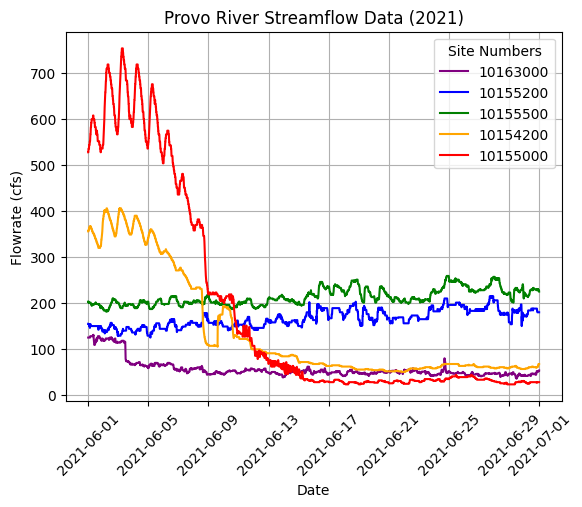

In [15]:
# Plot each site's streamflow data with custom colors and legend labels
plt.plot(x, y_1, label='10163000', color='purple')
plt.plot(x, y_2, label='10155200', color='blue')
plt.plot(x, y_3, label='10155500', color='green')
plt.plot(x, y_4, label='10154200', color='orange')
plt.plot(x, y_5, label='10155000', color='red')

# Add the title, axis labels, and rotate date ticks for readability
plt.title('Provo River Streamflow Data (2021)')
plt.xlabel('Date')
plt.ylabel('Flowrate (cfs)')
plt.xticks(rotation=45)

# Add a legend with a title and gridlines
plt.legend(title='Site Numbers')
plt.grid(True)

# Display the completed graph
plt.show()

### Part 4 - Bicycle Count in Fremont

You will now create a graph using bicycle count data of a bridge in Fremont, Seattle.

### Numpy Array Creation & Slicing

Create and slice the array to create the x and y-axis values. These will correspond to the following columns in the CSV linked on on the HW instructions page:

*   x - Date
*   y_1 - Fremont Bridge Total
*   y_2 - Fremont Bridge East Sidewalk
*   y_3 - Fremont Bridge West Sidewalk

In [20]:
# Import the Fremont bridge count CSV file into a 2D array of strings
array1 = np.genfromtxt('Fremont-Bridge-Bicycle-Count.csv', delimiter=',', dtype=str, skip_header=1)

# Slice the columns and convert data types
x = array1[:, 0].astype('datetime64') # ai helped learn the 'datetime64' callout, which basically just tells Python to treat the text like an actual calendar date, not just regular words or a string.
y_1 = array1[:, 1].astype(float)
y_2 = array1[:, 2].astype(float)
y_3 = array1[:, 3].astype(float)

### Graphing the Data

Plot x, y_1, y_2, and y_3 in this code block.

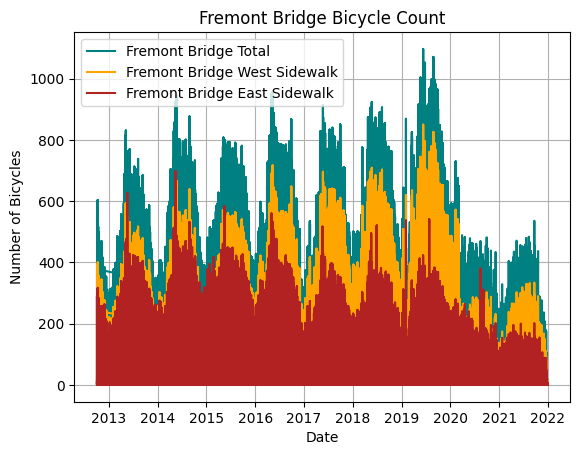

In [19]:
# Plot the bicycle counts with custom colors and labels
plt.plot(x, y_1, label='Fremont Bridge Total', color='teal')
plt.plot(x, y_3, label='Fremont Bridge West Sidewalk', color='orange')
plt.plot(x, y_2, label='Fremont Bridge East Sidewalk', color='firebrick')

# Add the title, axis labels, legend, and gridlines
plt.title('Fremont Bridge Bicycle Count')
plt.xlabel('Date')
plt.ylabel('Number of Bicycles')
plt.legend()
plt.grid(True)

# Display the completed graph
plt.show()

# Comment: Bicycle counts in later years, especially 2020-2022 are likely a lot lower due to more people working from home and a change in the regular patterns.

### Part 5 - Average U.S. Daily Birth Data

You will now create a graph using average daily birth data in the U.S.

### Numpy Array Creation & Slicing

Slice the array to create the x and y-axis values. These will correspond to the following columns in the CSV linked on the HW instructions page:

*   x - Date
*   y_1 - Births

In [23]:
# Import the U.S. birth data CSV file into a 2D array of strings
array1 = np.genfromtxt('2012-US-Birth-Rates.csv', delimiter=',', dtype=str, skip_header=1)

# Slice the columns and convert data types
x = array1[:, 0].astype('datetime64') # ai helped learn the 'datetime64' callout, which basically just tells Python to treat the text like an actual calendar date, not just regular words or a string.
y_1 = array1[:, 1].astype(float)

### Graphing the Data

Plot x and y_1 with the elements shown in the instructions in the code block below.

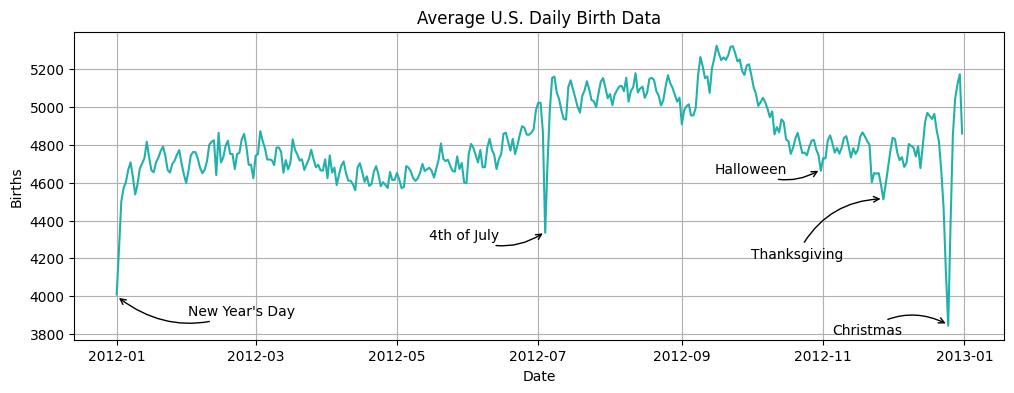

In [48]:
# Set the figure size
plt.figure(figsize=(12, 4))

# Plot the daily birth data
plt.plot(x, y_1, color='lightseagreen')

# Add curved arrows and text annotations using datetime64 for both coordinates
plt.annotate("New Year's Day", xy=(np.datetime64('2012-01-01'), 4000), xytext=(np.datetime64('2012-02-01'), 3900),
             arrowprops=dict(facecolor='black', arrowstyle='->', connectionstyle='arc3,rad=-0.3'))

plt.annotate("4th of July", xy=(np.datetime64('2012-07-04'), 4340), xytext=(np.datetime64('2012-05-15'), 4300),
             arrowprops=dict(facecolor='black', arrowstyle='->', connectionstyle='arc3,rad=0.3'))

plt.annotate("Halloween", xy=(np.datetime64('2012-10-31'), 4670), xytext=(np.datetime64('2012-09-15'), 4650),
             arrowprops=dict(facecolor='black', arrowstyle='->', connectionstyle='arc3,rad=0.3'))

plt.annotate("Thanksgiving", xy=(np.datetime64('2012-11-27'), 4515), xytext=(np.datetime64('2012-10-01'), 4200),
             arrowprops=dict(facecolor='black', arrowstyle='->', connectionstyle='arc3,rad=-0.3'))

plt.annotate("Christmas", xy=(np.datetime64('2012-12-25'), 3850), xytext=(np.datetime64('2012-11-05'), 3800),
             arrowprops=dict(facecolor='black', arrowstyle='->', connectionstyle='arc3,rad=-0.3'))

# Add title, axis labels, and gridlines
plt.title('Average U.S. Daily Birth Data')
plt.xlabel('Date')
plt.ylabel('Births')
plt.grid(True)

# Display the completed graph
plt.show()

# Comment: Birth rates drop sharply on holidays like New Year's Day, 4th of July, Halloween, Thanksgiving, and Christmas because hospitals schedule fewer procedures and inductions on those days.